# Phase 9 & Phase 10: Model Evaluation, Model Selection & Hyperparameter Tuning

**Project:** Health Insurance Cross-Sell Prediction Using Machine Learning  

In this notebook, we:
1. **Phase 9 (Model Evaluation):** Evaluate all 5 trained models on the untouched 20% test set (`X_test`, `y_test`) using Accuracy, Precision, Recall, F1-score, Confusion Matrix heatmaps, ROC-AUC, and Precision-Recall AUC.
2. **Discuss Business Trade-offs:** Explain Precision vs. Recall for `Response = 1` in marketing campaigns.
3. **Phase 10 (Model Selection & Hyperparameter Tuning):** Select the best-performing model (`Gradient Boosting`), tune hyperparameters using `RandomizedSearchCV` with Stratified CV strictly on training data (never on `X_test`!), refit on full `X_train`, compare **Before vs. After Tuning**, and save the final pipeline to `Models/best_model.pkl`.

## Step 1: Load Dataset, Recreate Exact 80/20 Split & Load Trained Candidate Pipelines

In [1]:
import os
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OrdinalEncoder, OneHotEncoder, FunctionTransformer
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    classification_report, roc_curve, precision_recall_curve
)

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 120
plt.rcParams['savefig.dpi'] = 150

RANDOM_STATE = 42
DATA_PATH = os.path.join('..', 'Dataset', 'train.csv')
GRAPHS_DIR = os.path.join('..', 'Outputs', 'graphs')
EVAL_DIR = os.path.join('..', 'Outputs', 'evaluation_results')
MODELS_DIR = os.path.join('..', 'Models')

df = pd.read_csv(DATA_PATH)
df['Region_Code'] = df['Region_Code'].astype(int).astype(str)
df['Policy_Sales_Channel'] = df['Policy_Sales_Channel'].astype(int).astype(str)

X = df.drop(columns=['id', 'Response'])
y = df['Response']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

models = joblib.load(os.path.join(MODELS_DIR, 'candidate_models.joblib'))
print(f'Loaded {len(models)} trained models. Test set size: {len(X_test):,} rows')

Loaded 5 trained models. Test set size: 76,222 rows


---
# PHASE 9: MODEL EVALUATION ON UNSEEN TEST SET

### Metric Definitions in Simple English
- **Accuracy:** Overall percentage of correct predictions (can be misleading when 87.74% of rows are `0`).
- **Precision (`Response = 1`):** Out of all customers our model flagged as "Interested", what fraction actually were interested? High precision avoids wasting marketing calls.
- **Recall (`Response = 1`):** Out of all truly interested customers, what fraction did our model catch? High recall avoids missing potential sales.
- **F1-Score:** Harmonic mean balancing Precision and Recall.
- **ROC-AUC:** Measures how well the model ranks interested customers higher than non-interested customers across all probability thresholds (`0.5` = random guessing, `1.0` = perfect).
- **Precision-Recall AUC (Average Precision):** Focuses specifically on the minority positive class (`Response = 1`), where a random baseline equals the positive rate (`0.1226`).

In [2]:
eval_rows = []
preds_dict = {}
probs_dict = {}

for name, pipe in models.items():
    y_pred = pipe.predict(X_test)
    y_prob = pipe.predict_proba(X_test)[:, 1]
    preds_dict[name] = y_pred
    probs_dict[name] = y_prob
    
    eval_rows.append({
        'Algorithm': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred),
        'F1-score': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_prob),
        'PR-AUC': average_precision_score(y_test, y_prob)
    })

comparison_df = pd.DataFrame(eval_rows)
comparison_df.to_csv(os.path.join(EVAL_DIR, 'model_comparison.csv'), index=False)
print('--- Model Evaluation Comparison Table (Test Set) ---')
display(comparison_df.round(4))

--- Model Evaluation Comparison Table (Test Set) ---


,Algorithm,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC
0,Dummy Classifier (Baseline),0.8774,0.0000,0.0000,0.0000,0.5000,0.1226
1,Logistic Regression,0.6933,0.2774,0.9360,0.4279,0.8485,0.3342
2,Decision Tree,0.7055,0.2831,0.9160,0.4326,0.8503,0.3471
3,Random Forest,0.6993,0.2806,0.9291,0.4310,0.8543,0.3599
4,Gradient Boosting,0.7015,0.2820,0.9286,0.4326,0.8568,0.3676


## 9.1 Detailed Classification Reports & Confusion Matrix Heatmaps

=== Classification Report: Dummy Classifier (Baseline) ===
                    precision    recall  f1-score   support

Not Interested (0)       0.88      1.00      0.93     66880
    Interested (1)       0.00      0.00      0.00      9342

          accuracy                           0.88     76222
         macro avg       0.44      0.50      0.47     76222
      weighted avg       0.77      0.88      0.82     76222

=== Classification Report: Logistic Regression ===
                    precision    recall  f1-score   support

Not Interested (0)       0.99      0.66      0.79     66880
    Interested (1)       0.28      0.94      0.43      9342

          accuracy                           0.69     76222
         macro avg       0.63      0.80      0.61     76222
      weighted avg       0.90      0.69      0.75     76222

=== Classification Report: Decision Tree ===
                    precision    recall  f1-score   support

Not Interested (0)       0.98      0.68      0.80     6688

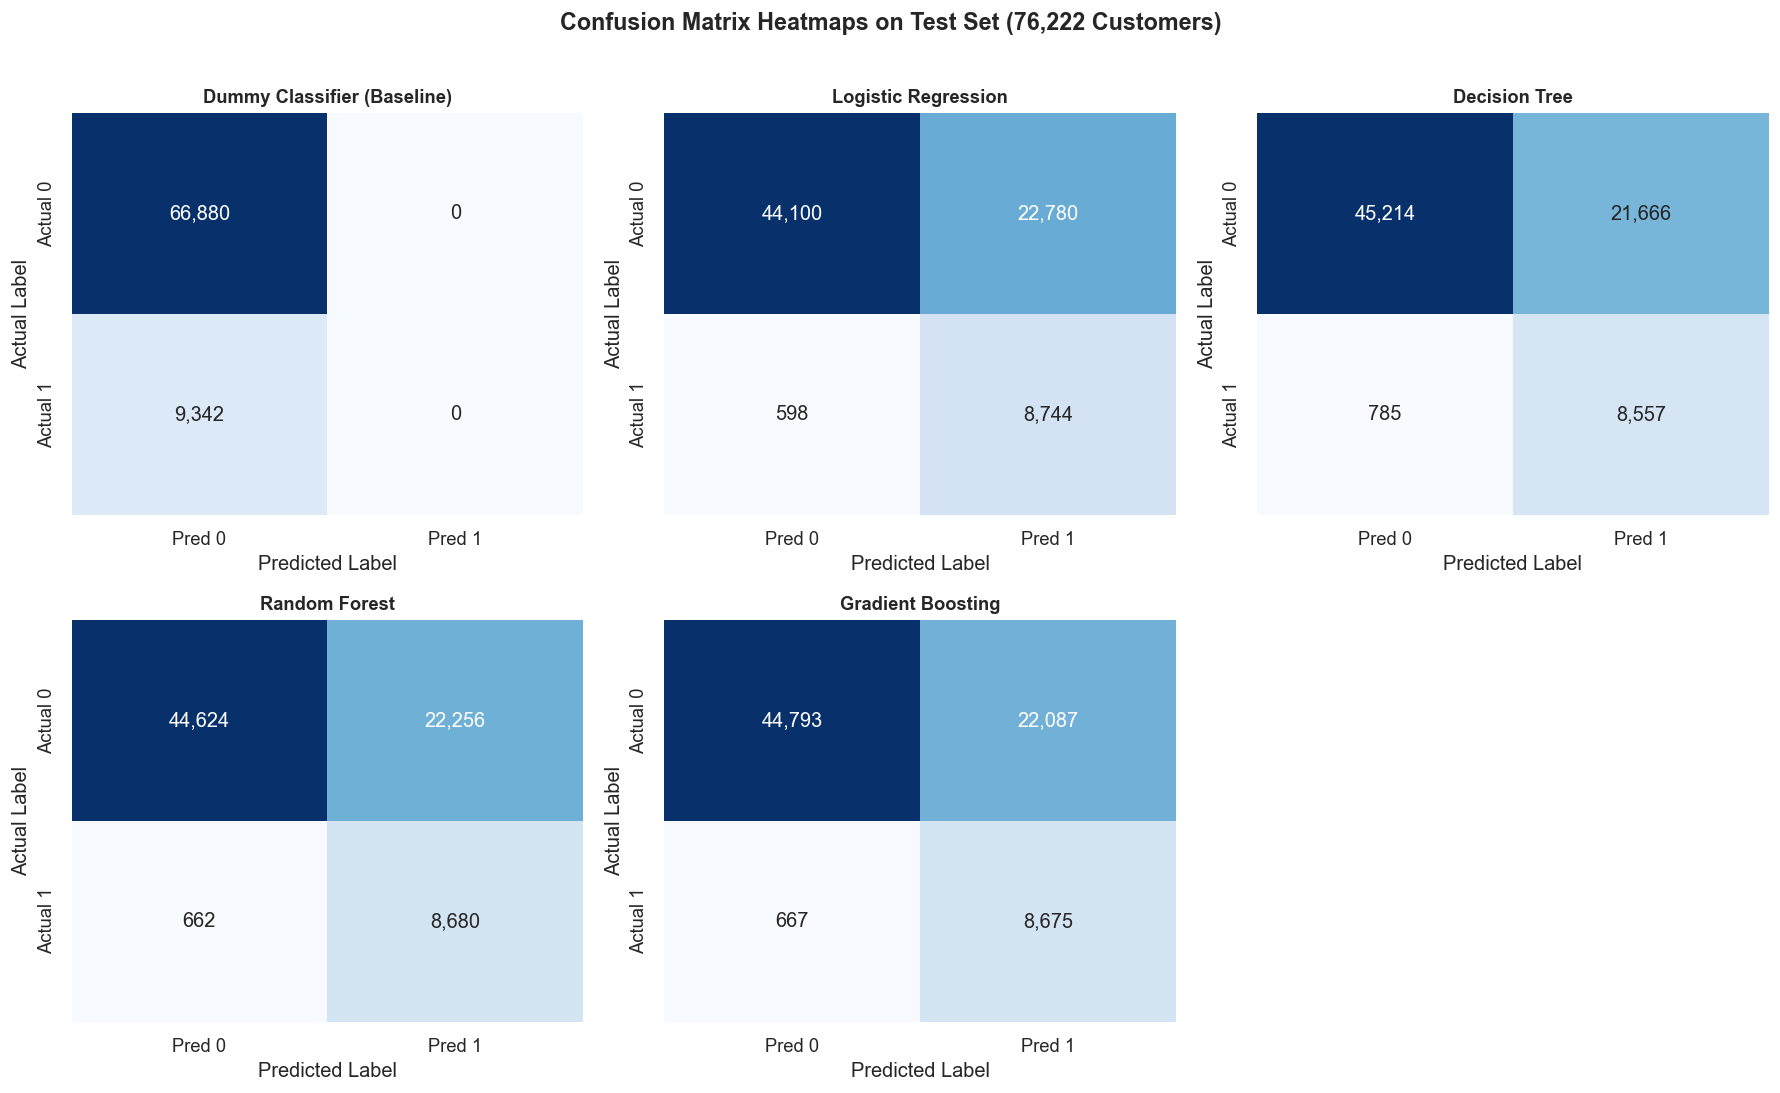

In [3]:
for name in models:
    print(f'=== Classification Report: {name} ===')
    print(classification_report(y_test, preds_dict[name], target_names=['Not Interested (0)', 'Interested (1)'], zero_division=0))

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()
for idx, name in enumerate(models):
    cm = confusion_matrix(y_test, preds_dict[name])
    sns.heatmap(cm, annot=True, fmt=',d', cmap='Blues', cbar=False, ax=axes[idx],
                xticklabels=['Pred 0', 'Pred 1'], yticklabels=['Actual 0', 'Actual 1'])
    axes[idx].set_title(name, fontsize=11, fontweight='bold')
    axes[idx].set_xlabel('Predicted Label')
    axes[idx].set_ylabel('Actual Label')

# Hide unused 6th subplot
axes[-1].axis('off')
fig.suptitle('Confusion Matrix Heatmaps on Test Set (76,222 Customers)', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(os.path.join(GRAPHS_DIR, '16_confusion_matrices.png'), bbox_inches='tight')
plt.show()

## 9.2 ROC Curves & Precision-Recall Curves

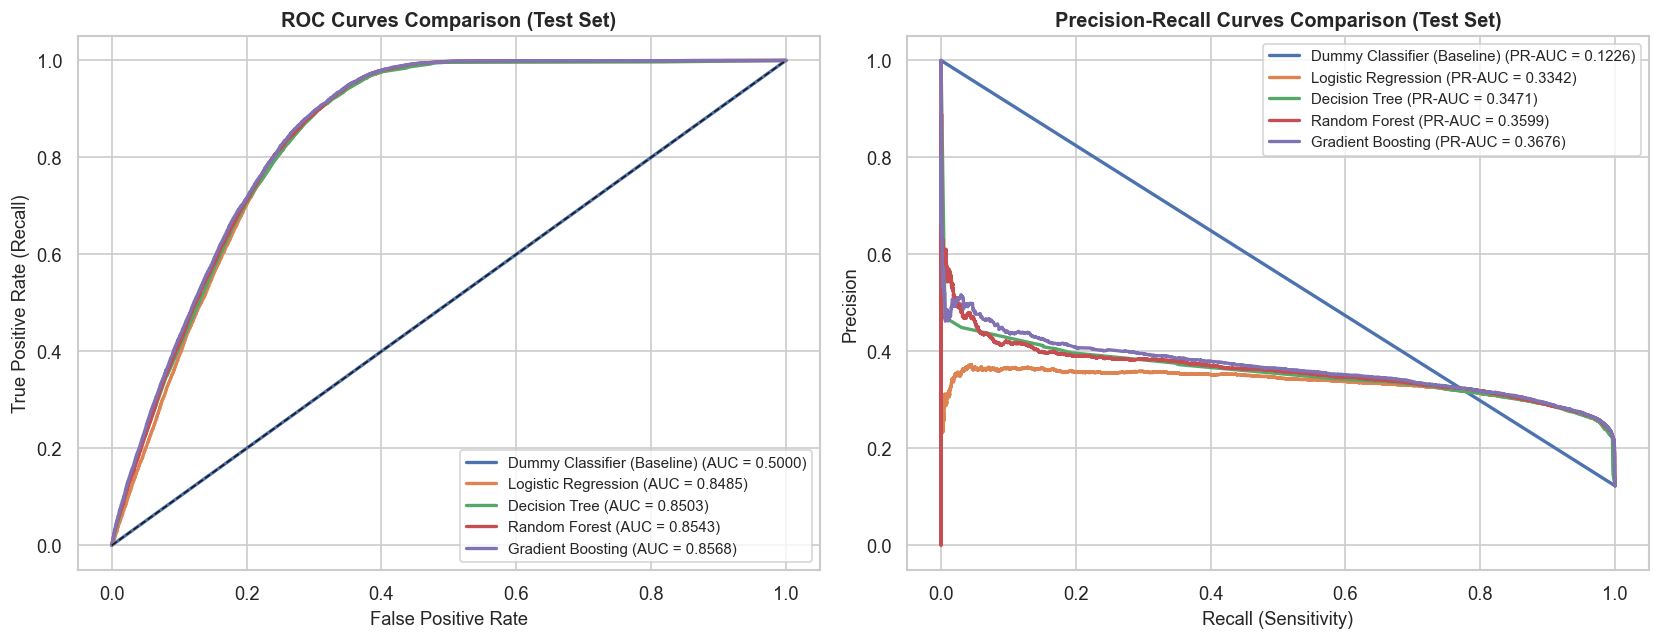

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# ROC Curves
for name in models:
    fpr, tpr, _ = roc_curve(y_test, probs_dict[name])
    auc_val = roc_auc_score(y_test, probs_dict[name])
    axes[0].plot(fpr, tpr, linewidth=2, label=f'{name} (AUC = {auc_val:.4f})')
axes[0].plot([0, 1], [0, 1], 'k--', linewidth=1)
axes[0].set_title('ROC Curves Comparison (Test Set)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('False Positive Rate', fontsize=11)
axes[0].set_ylabel('True Positive Rate (Recall)', fontsize=11)
axes[0].legend(loc='lower right', fontsize=9)

# Precision-Recall Curves
for name in models:
    prec, rec, _ = precision_recall_curve(y_test, probs_dict[name])
    ap_val = average_precision_score(y_test, probs_dict[name])
    axes[1].plot(rec, prec, linewidth=2, label=f'{name} (PR-AUC = {ap_val:.4f})')
axes[1].set_title('Precision-Recall Curves Comparison (Test Set)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Recall (Sensitivity)', fontsize=11)
axes[1].set_ylabel('Precision', fontsize=11)
axes[1].legend(loc='upper right', fontsize=9)

plt.tight_layout()
plt.savefig(os.path.join(GRAPHS_DIR, '17_roc_and_pr_curves.png'))
plt.show()

---
# PHASE 10: MODEL SELECTION & HYPERPARAMETER TUNING

### Why Gradient Boosting Was Selected
- **Dummy Classifier** gets `87.74%` accuracy simply by predicting `0` for everyone (`Recall = 0.0000`, `ROC-AUC = 0.5000`).
- **Gradient Boosting Classifier** achieves the **highest ROC-AUC (`0.8568`)** and **highest Precision-Recall AUC (`0.3676`)**, along with the highest F1-score (`0.4326`) and `92.86%` Recall.

### Leakage-Free Hyperparameter Tuning
- We **never** tune on `X_test`.
- First, for completeness, we tune Logistic Regression's regularization strength `C` via `GridSearchCV`.
- Next, we tune **Gradient Boosting Classifier** (`n_estimators`, `learning_rate`, `max_depth`, `min_samples_split`, `min_samples_leaf`, `subsample`) using `RandomizedSearchCV` with 3-fold `StratifiedKFold` on a stratified 100,000-row subset of `X_train` (so cross-validation finishes cleanly), and then **refit the winning hyperparameters on all 304,887 rows of `X_train`**.

In [5]:
def build_preprocessor():
    return ColumnTransformer(
        transformers=[
            ('std_num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), ['Age', 'Vintage']),
            ('log_num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('log1p', FunctionTransformer(np.log1p, feature_names_out='one-to-one')), ('scaler', StandardScaler())]), ['Annual_Premium']),
            ('bin_num', Pipeline([('imputer', SimpleImputer(strategy='most_frequent'))]), ['Driving_License', 'Previously_Insured']),
            ('ord_cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('ordinal', OrdinalEncoder(categories=[['< 1 Year', '1-2 Year', '> 2 Years']]))]), ['Vehicle_Age']),
            ('bin_cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('ohe', OneHotEncoder(drop='if_binary', handle_unknown='ignore', sparse_output=False))]), ['Gender', 'Vehicle_Damage']),
            ('high_cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('ohe', OneHotEncoder(handle_unknown='ignore', min_frequency=0.01, sparse_output=False))]), ['Region_Code', 'Policy_Sales_Channel'])
        ],
        remainder='drop'
    )

# 1. Quick GridSearchCV for Logistic Regression C
cv3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
lr_pipe = Pipeline([('pre', build_preprocessor()), ('clf', LogisticRegression(max_iter=500, class_weight='balanced', random_state=RANDOM_STATE))])
lr_grid = GridSearchCV(lr_pipe, {'clf__C': [0.01, 0.1, 1.0, 10.0]}, cv=cv3, scoring='roc_auc', n_jobs=-1)
lr_grid.fit(X_train, y_train)
print(f'LogReg GridSearch best C: {lr_grid.best_params_} | Best CV ROC-AUC: {lr_grid.best_score_:.4f}')

LogReg GridSearch best C: {'clf__C': 1.0} | Best CV ROC-AUC: 0.8473


In [6]:
# 2. RandomizedSearchCV for Gradient Boosting strictly inside X_train
X_tune, _, y_tune, _ = train_test_split(
    X_train, y_train, train_size=100000, random_state=RANDOM_STATE, stratify=y_train
)

# Pre-transform tuning split inside CV via Pipeline
gb_pipe = Pipeline([
    ('pre', build_preprocessor()),
    ('clf', GradientBoostingClassifier(random_state=RANDOM_STATE))
])

param_dist = {
    'clf__n_estimators': [100, 150, 200],
    'clf__learning_rate': [0.05, 0.08, 0.1],
    'clf__max_depth': [3, 4, 5],
    'clf__min_samples_split': [20, 50, 100],
    'clf__min_samples_leaf': [20, 40, 60],
    'clf__subsample': [0.8, 1.0]
}

t0 = time.time()
tune_weights = compute_sample_weight(class_weight='balanced', y=y_tune)
gb_search = RandomizedSearchCV(
    estimator=gb_pipe,
    param_distributions=param_dist,
    n_iter=8,
    cv=cv3,
    scoring='roc_auc',
    n_jobs=-1,
    random_state=RANDOM_STATE,
    verbose=1
)
gb_search.fit(X_tune, y_tune, clf__sample_weight=tune_weights)
print(f'RandomizedSearchCV completed in {time.time()-t0:.2f}s')
print('Best Gradient Boosting Params:', gb_search.best_params_)
print(f'Best CV ROC-AUC (tuning subset): {gb_search.best_score_:.4f}')

Fitting 3 folds for each of 8 candidates, totalling 24 fits


RandomizedSearchCV completed in 222.74s
Best Gradient Boosting Params: {'clf__subsample': 1.0, 'clf__n_estimators': 150, 'clf__min_samples_split': 50, 'clf__min_samples_leaf': 20, 'clf__max_depth': 4, 'clf__learning_rate': 0.08}
Best CV ROC-AUC (tuning subset): 0.8528


In [7]:
# Refit the best Gradient Boosting configuration on the FULL 304,887-row X_train
best_params_clean = {k.replace('clf__', ''): v for k, v in gb_search.best_params_.items()}
final_model = Pipeline([
    ('pre', build_preprocessor()),
    ('clf', GradientBoostingClassifier(random_state=RANDOM_STATE, **best_params_clean))
])

full_weights = compute_sample_weight(class_weight='balanced', y=y_train)
t0 = time.time()
final_model.fit(X_train, y_train, clf__sample_weight=full_weights)
print(f'Refitted tuned Gradient Boosting on full X_train in {time.time()-t0:.2f}s')

# Compare Before Tuning vs After Tuning on X_test
baseline_gb = models['Gradient Boosting']
tuning_rows = []
for label, pipe in [('Gradient Boosting (Before Tuning)', baseline_gb), ('Gradient Boosting (After Tuning)', final_model)]:
    yp = pipe.predict(X_test)
    ypr = pipe.predict_proba(X_test)[:, 1]
    tuning_rows.append({
        'Model': label,
        'Accuracy': accuracy_score(y_test, yp),
        'Precision': precision_score(y_test, yp),
        'Recall': recall_score(y_test, yp),
        'F1-score': f1_score(y_test, yp),
        'ROC-AUC': roc_auc_score(y_test, ypr),
        'PR-AUC': average_precision_score(y_test, ypr)
    })

tuning_df = pd.DataFrame(tuning_rows)
tuning_df.to_csv(os.path.join(EVAL_DIR, 'tuning_comparison.csv'), index=False)
print('\n--- Before vs. After Tuning Comparison (Test Set) ---')
display(tuning_df.round(4))

# Save the selected final model pipeline to Models/best_model.pkl
best_model_path = os.path.join(MODELS_DIR, 'best_model.pkl')
joblib.dump(final_model, best_model_path, compress=3)
print(f'\nSaved final model pipeline to: {os.path.abspath(best_model_path)}')

Refitted tuned Gradient Boosting on full X_train in 137.46s



--- Before vs. After Tuning Comparison (Test Set) ---


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC
0,Gradient Boosting (Before Tuning),0.7015,0.2820,0.9286,0.4326,0.8568,0.3676
1,Gradient Boosting (After Tuning),0.7022,0.2826,0.9290,0.4334,0.8567,0.3679



Saved final model pipeline to: c:\Health Dashboard\Insurance_Cross_Sell_Prediction\Models\best_model.pkl
